In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [98]:
##### calibration
# at lab-pressure and temperature
U_lab = 150 # measurement
p_lab = 1 # measurement

# low-pressure (# evacuate pump (7-10min))
U_2 = 0.015 # measurement
p_2 = 0.0001 # +- 0.0001 bar

x = np.array([U_lab, U_2])
y = np.array([p_lab, p_2])

In [99]:
def pr_U (U, p_0, C):
    return p_0 + U * C

5.92132121113309e-10 0.00666666666271909


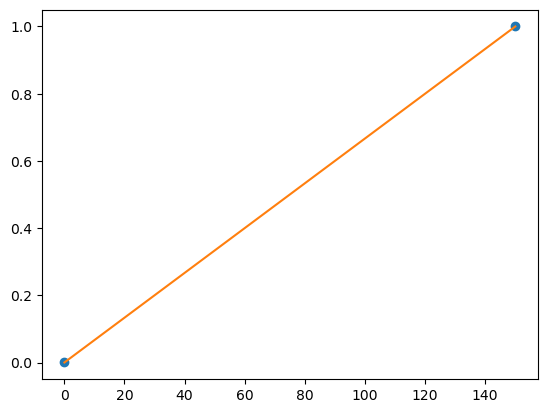

In [100]:
popt, pcov = curve_fit(pr_U, np.array([U_lab, U_2]), np.array([p_lab, p_2]), absolute_sigma=True)
p_0 = popt[0]
C = popt[1]
print(p_0, C)
plt.plot(x, y, marker='o', linestyle='')
plt.plot(np.linspace(np.min(x), np.max(x), 20), pr_U(np.linspace(np.min(x), np.max(x), 20), p_0, C))

In [101]:
##### absolute zero
# evacuate pump (7-10min (maybe already done))
# fill with helium for at least two minutes
# repeat procedure once

In [102]:
# boiling water (close opening after heating)
U_k = 150 # measurment
t_k = 100 # table relation with pressure

p_k = pr_U(U_k, p_0, C)
print(p_k)

0.9999999999999956


In [109]:
# ice water
# make cold ice water wait ca 2min
U_e = 109.8 # measurment
t_e = 0 # temperature ice-water

p_e = pr_U(U_e, p_0, C)
print(p_e)

0.7320000001586882


In [110]:
##### calculations:
t_0_approx = (-1) * p_e * t_k / (p_k - p_e)
print(t_0_approx)

-273.13432857915376


In [111]:
epsilon = 10**(-3)
gamma = 10**(-5)

t_lab = 23 #measurment?

aa = (1 + epsilon) * p_e - (1 + epsilon + gamma * t_k) * p_k
bb = epsilon * (p_k - p_e) + (1 + gamma * t_k) * p_k * t_lab - p_e * (t_lab + t_k)
cc = p_e * t_lab * t_k

print(((-1) * bb + np.sqrt(bb**2 - 4 * aa * cc)) / (2 * aa))
print(((-1) * bb - np.sqrt(bb**2 - 4 * aa * cc)) / (2 * aa))

t_0 = ((-1) * bb + np.sqrt(bb**2 - 4 * aa * cc)) / (2 * aa)
print('t_0 =', t_0)

-271.8683102545327
22.99829206056887
t_0 = -271.8683102545327


In [115]:
##### liquid nitrogen
U_LN2 = 31 # measurement
p_LN2 = pr_U(U_LN2, p_0, C)
print(p_LN2)

0.2066666671364239


In [116]:
t_LN2_approx = (1 - p_LN2 / p_e) * t_0
print(t_LN2_approx)

-195.11131904123337


In [117]:
AAA = p_e / (t_e - t_0) + epsilon * (p_e - p_LN2) / (t_lab - t_0)
t_LN2 = (AAA * t_0 + p_LN2) / (AAA - gamma * p_LN2)

print(t_LN2)

-195.31189116513082
